<a href="https://colab.research.google.com/github/Ascavalc/Floripa/blob/main/Aula_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 14 — Árvore de decisão

Vamos usar a mesma ideia para dois resultados diferentes: identificar **alagamentos** e estimar **dias de atraso de contratos**. Em cada caso, a árvore será comparada aos modelos que já estudamos.

As duas bases são **simuladas para esta aula**. Os registros, limites de cadastro e relações entre as variáveis não representam medições nem regras oficiais da Prefeitura de Florianópolis. Foram construídos com mudanças por faixas e combinações de condições, para estudarmos relações não lineares.

Deixe os dois arquivos CSV na mesma pasta deste notebook e execute as células em ordem. Os CSVs usam ponto e vírgula como separador. No Colab, envie os dois arquivos para a área de arquivos. Se faltar alguma biblioteca, execute a instalação abaixo retirando o `#`.

In [1]:
# %pip install "pandas>=2.0" "numpy>=1.24" "matplotlib>=3.10" "scikit-learn>=1.4"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             ConfusionMatrixDisplay, r2_score, mean_squared_error,
                             root_mean_squared_error)

PASTA = Path.cwd()
SEMENTE = 42
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 12,
                     'font.size': 10})
AZUL, AZUL_ESCURO = '#1A76D5', '#0A2D5B'

## 1. Leitura e análise dos dados

Antes de treinar, precisamos entender o que cada linha representa, conferir tipos, faltantes e valores incompatíveis com o cadastro. Um valor afastado dos demais no boxplot é um sinal para investigar; sozinho, isso não justifica excluir a linha.

Usaremos as mesmas funções de análise nos dois exemplos.

In [2]:
def converter_numeros(serie):
    texto = serie.astype('string').str.strip().str.replace(',', '.', regex=False)
    return pd.to_numeric(texto, errors='coerce')

def resumo_ausentes(dados):
    return pd.DataFrame({'Ausentes': dados.isna().sum(),
                         'Percentual (%)': dados.isna().mean() * 100})

def distribuicoes(dados, colunas):
    fig, eixos = plt.subplots(len(colunas), 2, figsize=(12, 2.5 * len(colunas)))
    for i, coluna in enumerate(colunas):
        valores = dados[coluna].dropna()
        eixos[i, 0].hist(valores, bins=35, color=AZUL, edgecolor='white')
        eixos[i, 0].set(title=coluna, ylabel='Quantidade de registros')
        eixos[i, 1].boxplot(valores, orientation='horizontal', patch_artist=True,
                            boxprops={'facecolor': '#D8EAF9'})
        eixos[i, 1].set(title=f'Boxplot: {coluna}', xlabel='Valor observado')
        if coluna == 'valor_contrato_reais':
            for ax in eixos[i]:
                ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x / 1e6:g}'))
                ax.set_xlabel('Valor contratado (milhões de reais)')
    plt.tight_layout()
    plt.show()

def analisar_cauda(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'Mínimo': serie.min(), 'Mediana': serie.median(),
                      'Percentil 90': serie.quantile(.90), 'Percentil 95': serie.quantile(.95),
                      'Percentil 99': serie.quantile(.99), 'Máximo': serie.max(),
                      'Assimetria': serie.skew(), 'Limite inferior do boxplot': limite_inferior,
                      'Limite superior do boxplot': limite_superior,
                      'Pontos fora desses limites': ((serie < limite_inferior) |
                                                    (serie > limite_superior)).sum()})

## 2. Defesa Civil — classificação de alagamentos

Cada linha representa uma região em um episódio de chuva. A resposta é `houve_alagamento`: **1 = houve** e **0 = não houve**. Usamos as condições do episódio para estudar sua associação com o alagamento; este exemplo não é um sistema de previsão meteorológica antecipada.

| Coluna | O que representa |
|---|---|
| chuva_24h_mm | Chuva acumulada em 24 horas, em milímetros |
| impermeabilizacao_pct | Percentual da área coberta por superfícies impermeáveis |
| capacidade_drenagem_mm_h | Capacidade estimada de drenagem, em milímetros por hora |
| chuva_72h_mm | Chuva acumulada em 72 horas, em milímetros |
| cota_terreno_m | Altitude local, em metros |
| nivel_mare_m | Nível da maré, em metros |
| distancia_rio_m | Distância ao rio, em metros |
| houve_alagamento | Resultado observado; será o alvo |

In [3]:
civil_bruta = pd.read_csv(PASTA / 'Aula_14_defesa_civil.csv', sep=';', encoding='utf-8-sig')
print(f'{civil_bruta.shape[0]:,} linhas e {civil_bruta.shape[1]} colunas')
display(civil_bruta.head())
display(resumo_ausentes(civil_bruta))
display(civil_bruta.dtypes.to_frame('Tipo lido'))

5,000 linhas e 8 colunas


,chuva_24h_mm,impermeabilizacao_pct,capacidade_drenagem_mm_h,chuva_72h_mm,cota_terreno_m,nivel_mare_m,distancia_rio_m,houve_alagamento
0,49.9,47.100,42.300,80.600,6.400,0.270,"2,269.000",1
1,23.9,88.400,31.800,120.700,NaN,1.100,NaN,0
2,22.9,40.300,25.200,66.400,14.700,0.610,NaN,0
3,80.4,82.100,44.100,106.700,11.600,1.030,"2,450.000",0
4,9.7,59.300,28.200,37.800,7.500,0.710,NaN,0


,Ausentes,Percentual (%)
chuva_24h_mm,0,0.000
impermeabilizacao_pct,0,0.000
capacidade_drenagem_mm_h,0,0.000
chuva_72h_mm,1000,20.000
cota_terreno_m,250,5.000
nivel_mare_m,2500,50.000
distancia_rio_m,2500,50.000
houve_alagamento,0,0.000


,Tipo lido
chuva_24h_mm,object
impermeabilizacao_pct,float64
capacidade_drenagem_mm_h,float64
chuva_72h_mm,float64
cota_terreno_m,float64
nivel_mare_m,float64
distancia_rio_m,float64
houve_alagamento,int64


### 2.1 Formato, distribuição e outliers

Alguns números vieram com vírgula decimal e espaços. Vamos padronizar a escrita antes da análise. A base tem duas colunas com 50% de ausentes, uma com 20% e outra com 5%.

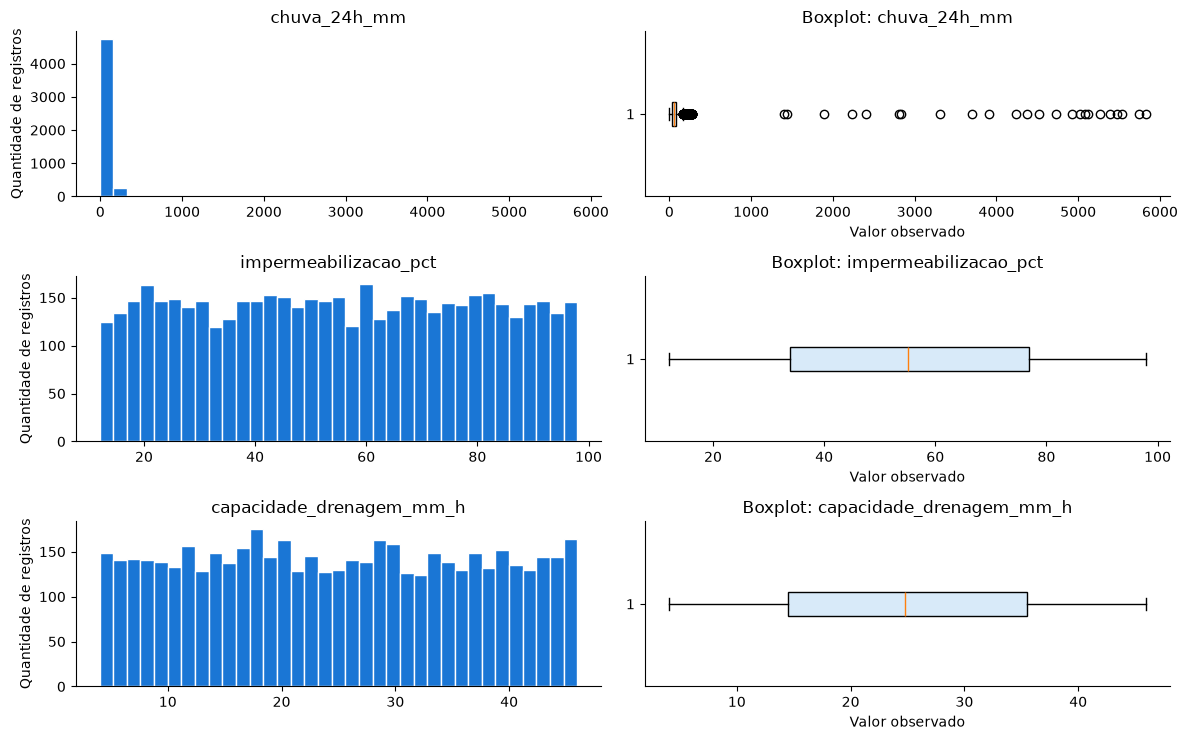

,Chuva em 24 h
Mínimo,-10.000
Mediana,51.900
Percentil 90,126.400
Percentil 95,158.710
Percentil 99,232.802
Máximo,"5,835.000"
Assimetria,15.635
Limite inferior do boxplot,-57.562
Limite superior do boxplot,170.537
Pontos fora desses limites,179.000


In [ ]:
civil_formatada = civil_bruta.apply(converter_numeros)
distribuicoes(civil_formatada, ['chuva_24h_mm', 'impermeabilizacao_pct',
                               'capacidade_drenagem_mm_h'])
display(analisar_cauda(civil_formatada['chuva_24h_mm']).to_frame('Chuva em 24 h'))

### 2.2 Limpeza e dados ausentes

Neste cadastro simulado, o sensor de chuva aceita leituras de **0 a 300 mm em 24 h**. Valores negativos ou acima do limite são erros inseridos para o exercício. Não estamos afirmando que 300 mm seja um limite da natureza. Leituras altas dentro da faixa serão preservadas, mesmo quando aparecerem fora dos limites do boxplot.

Retiraremos `nivel_mare_m` e `distancia_rio_m`: nesta atividade, metade das medições está ausente e não temos uma fonte para recuperá-las. **50% não é uma regra universal de exclusão.**

Para preencher as demais colunas antes da divisão, usaremos referências fixadas para o exercício: 120 mm para chuva em 72 h e 11 m para cota do terreno. A chuva de 72 h não pode ficar menor que a de 24 h. Criaremos também uma coluna indicando cada preenchimento, para não confundir uma medida observada com um valor substituído.

Essas referências não foram calculadas a partir da base. Quando o preenchimento usa média ou mediana aprendida dos dados, ela precisa ser calculada **somente no treino** e aplicada ao teste. A padronização dos modelos lineares também será aprendida somente no treino.

Removidas: 30 | Mantidas: 4970


,Ausentes,Percentual (%)
chuva_24h_mm,0,0.000
impermeabilizacao_pct,0,0.000
capacidade_drenagem_mm_h,0,0.000
chuva_72h_mm,0,0.000
cota_terreno_m,0,0.000
houve_alagamento,0,0.000
chuva_72h_mm_ausente,0,0.000
cota_terreno_m_ausente,0,0.000


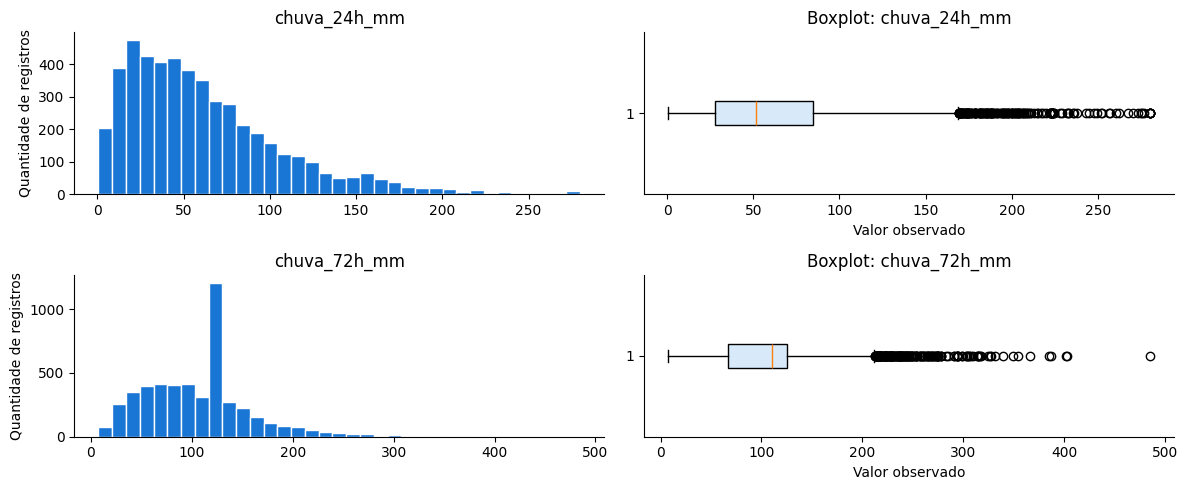

,Após a limpeza
Mínimo,0.600
Mediana,51.800
Percentil 90,123.700
Percentil 95,156.355
Percentil 99,210.555
Máximo,280.000
Assimetria,1.336
Limite inferior do boxplot,-56.813
Limite superior do boxplot,169.088
Pontos fora desses limites,163.000


In [4]:
def limpar_civil(dados):
    d = dados.apply(converter_numeros).drop_duplicates().copy()
    valido = (d['chuva_24h_mm'].between(0, 300) &
              d['impermeabilizacao_pct'].between(0, 100) &
              d['capacidade_drenagem_mm_h'].between(0, 60))
    if 'houve_alagamento' in d:
        valido &= d['houve_alagamento'].isin([0, 1])
    d = d.loc[valido].copy()
    d.loc[~d['cota_terreno_m'].between(0, 100), 'cota_terreno_m'] = np.nan
    incoerente = (d['chuva_72h_mm'] < d['chuva_24h_mm']) | (d['chuva_72h_mm'] > 900)
    d.loc[incoerente, 'chuva_72h_mm'] = np.nan
    d = d.drop(columns=['nivel_mare_m', 'distancia_rio_m'], errors='ignore')
    for coluna, referencia in {'chuva_72h_mm': 120.0, 'cota_terreno_m': 11.0}.items():
        d[coluna + '_ausente'] = d[coluna].isna().astype(int)
        d[coluna] = d[coluna].fillna(referencia)
    d['chuva_72h_mm'] = np.maximum(d['chuva_72h_mm'], d['chuva_24h_mm'])
    return d

civil = limpar_civil(civil_bruta)
print(f'Removidas: {len(civil_bruta) - len(civil)} | Mantidas: {len(civil)}')
display(resumo_ausentes(civil))
distribuicoes(civil, ['chuva_24h_mm', 'chuva_72h_mm'])
display(analisar_cauda(civil['chuva_24h_mm']).to_frame('Após a limpeza'))

O histograma mostra a frequência de cada faixa. A cauda à direita reúne chuvas mais intensas e menos frequentes. O percentil 95 é o valor abaixo do qual estão 95% das leituras. Esses casos extremos, quando válidos, interessam justamente à Defesa Civil; por isso não aplicamos um corte automático pelo boxplot. Na chuva de 72 h, parte da concentração perto de 120 mm foi criada pelo preenchimento: ela não corresponde apenas a medições reais.

Vamos observar agora a distribuição da resposta e a relação de duas entradas com o alagamento. Essa leitura é exploratória; não será usada para escolher cortes manuais para o modelo.

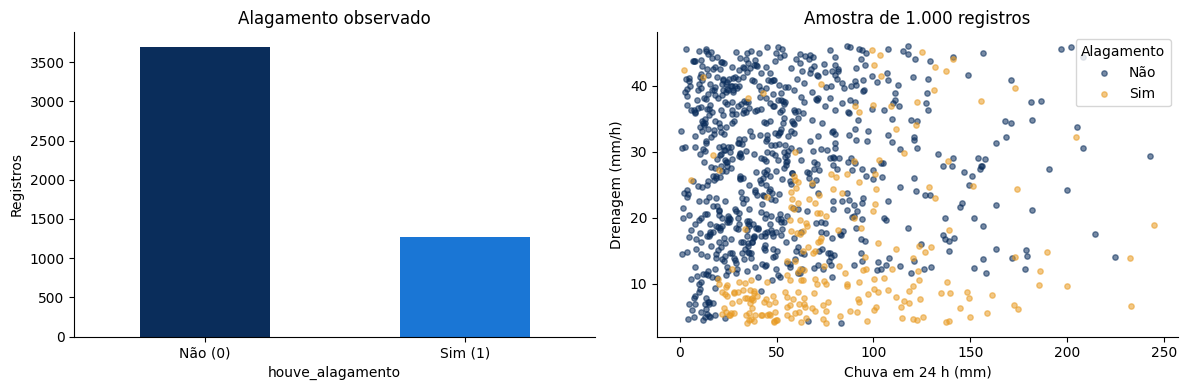

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
civil['houve_alagamento'].value_counts().sort_index().plot.bar(
    ax=ax[0], color=[AZUL_ESCURO, AZUL], rot=0)
ax[0].set(xticklabels=['Não (0)', 'Sim (1)'], title='Alagamento observado', ylabel='Registros')
amostra = civil.sample(1000, random_state=SEMENTE)
for classe, cor in [(0, AZUL_ESCURO), (1, '#E89B24')]:
    grupo = amostra[amostra['houve_alagamento'] == classe]
    ax[1].scatter(grupo['chuva_24h_mm'], grupo['capacidade_drenagem_mm_h'],
                  s=15, alpha=.55, color=cor, label='Sim' if classe else 'Não')
ax[1].set(xlabel='Chuva em 24 h (mm)', ylabel='Drenagem (mm/h)',
          title='Amostra de 1.000 registros')
ax[1].legend(title='Alagamento')
plt.tight_layout(); plt.show()

### 2.3 Treino, validação e teste

A limpeza está concluída. Vamos reservar 25% dos registros para o teste e manter proporções semelhantes das classes nos dois conjuntos (`stratify`). Os outros 75% serão usados para treinar e escolher as configurações por validação cruzada.

Na validação cruzada, dividimos o treino em cinco partes. Ajustamos em quatro e avaliamos na parte restante, alternando as cinco vezes. Escolheremos a configuração pelo **F1 médio**, sem consultar o teste. A regressão logística recebe padronização dentro de cada rodada; a árvore usa as medidas nas unidades originais.

In [6]:
X_c = civil.drop(columns='houve_alagamento')
y_c = civil['houve_alagamento'].astype(int)
Xc_treino, Xc_teste, yc_treino, yc_teste = train_test_split(
    X_c, y_c, test_size=.25, random_state=SEMENTE, stratify=y_c)
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
buscas_c = {
    'Regressão logística': GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
        {'logisticregression__C': [.01, .1, 1, 10, 100]}, scoring='f1', cv=cv_c),
    'Árvore de classificação': GridSearchCV(
        DecisionTreeClassifier(random_state=SEMENTE),
        {'max_depth': [2, 3, 4], 'min_samples_leaf': [20, 40, 80]}, scoring='f1', cv=cv_c)
}
for busca in buscas_c.values():
    busca.fit(Xc_treino, yc_treino)
display(pd.DataFrame([{'Modelo': nome, 'F1 na validação': busca.best_score_,
                       'Configuração': busca.best_params_} for nome, busca in buscas_c.items()]))

,Modelo,F1 na validação,Configuração
0,Regressão logística,0.661,{'logisticregression__C': 10}
1,Árvore de classificação,0.869,"{'max_depth': 4, 'min_samples_leaf': 20}"


### 2.4 Avaliação da classificação

**Acurácia** mede a proporção total de acertos. **Precisão** pergunta: entre os alertas de alagamento, quantos estavam certos? **Revocação** pergunta: entre os alagamentos reais, quantos encontramos? **F1** é a média harmônica da precisão e da revocação; fica baixo quando uma delas é baixa.

Usaremos a classe 1 como positiva e limiar de 0,50 nos dois modelos. A referência que sempre prevê a classe mais frequente ajuda a interpretar a acurácia. Todos serão avaliados nos mesmos registros de teste.

,Acurácia,F1,Precisão,Revocação
Modelo,,,,
Sempre a classe majoritária,0.743,0.000,0.000,0.000
Regressão logística,0.842,0.649,0.752,0.571
Árvore de classificação,0.944,0.881,0.959,0.815


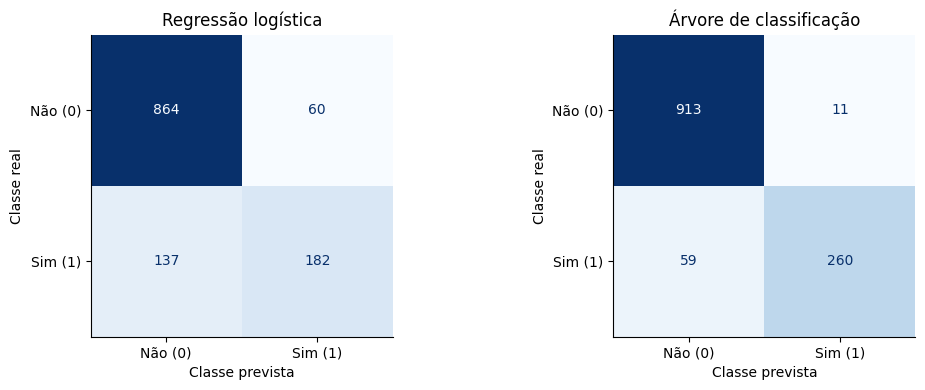

In [7]:
modelos_c = {nome: busca.best_estimator_ for nome, busca in buscas_c.items()}
previsoes_c = {nome: modelo.predict(Xc_teste) for nome, modelo in modelos_c.items()}
classe_majoritaria = yc_treino.mode().iloc[0]
avaliacoes_c = {'Sempre a classe majoritária': np.full(len(yc_teste), classe_majoritaria), **previsoes_c}
resultados_c = pd.DataFrame([
    {'Modelo': nome, 'Acurácia': accuracy_score(yc_teste, pred),
     'F1': f1_score(yc_teste, pred, zero_division=0),
     'Precisão': precision_score(yc_teste, pred, zero_division=0),
     'Revocação': recall_score(yc_teste, pred, zero_division=0)}
    for nome, pred in avaliacoes_c.items()]).set_index('Modelo')
display(resultados_c)
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, pred) in zip(eixos, previsoes_c.items()):
    ConfusionMatrixDisplay.from_predictions(yc_teste, pred, display_labels=['Não (0)', 'Sim (1)'],
        ax=ax, cmap='Blues', colorbar=False)
    ax.set(title=nome, xlabel='Classe prevista', ylabel='Classe real')
plt.tight_layout(); plt.show()

Na matriz, a diagonal reúne os acertos. O canto superior direito mostra **falsos positivos**: houve alerta, mas não houve alagamento. O canto inferior esquerdo mostra **falsos negativos**: houve alagamento e o modelo não identificou.

A árvore pode combinar condições diferentes em cada ramo. A regressão logística, com estas entradas e sem criar interações, usa uma fronteira linear no espaço das variáveis. Isso ajuda a entender a diferença de desempenho nesta base; não significa que a árvore será melhor em qualquer problema.

### 2.5 Leitura da árvore

A árvore é uma sequência de perguntas sobre os dados. **Começamos na caixa mais alta e seguimos um único caminho até uma folha.** A folha é uma caixa sem novos ramos abaixo dela: é ali que encontramos a previsão final.

Em cada caixa com uma condição, fazemos três passos:

1. Consultamos a variável indicada, como a capacidade de drenagem.
2. Comparamos o valor do novo caso com o corte escrito depois de `<=`, que significa **menor ou igual**.
3. Se a condição for verdadeira, seguimos à **esquerda** (`True`). Se for falsa, seguimos à **direita** (`False`). Repetimos isso na próxima caixa.

**Atenção: `True` não significa que houve alagamento.** Significa apenas que a condição daquela caixa foi atendida. A resposta sobre alagamento aparece na folha.

| Informação na caixa | Como interpretar |
|---|---|
| `node #0`, `node #1`… | Identificação do nó. Serve para localizá-lo no quadro do caminho; não é a previsão nem a profundidade. |
| `Drenagem (mm/h) <= 10.95` | Pergunta: a capacidade de drenagem é menor ou igual a 10,95 mm/h? |
| `samples` | Quantos registros de **treino** chegaram a esse nó. Nos ramos seguintes, o número diminui porque cada grupo contém apenas parte dos casos. |
| `value` | Distribuição dos resultados na ordem **[não houve alagamento, houve alagamento]**. Pode aparecer como contagem ou proporção, conforme a versão da biblioteca. |
| `class` | Classe mais frequente naquele nó. Antes da folha, é apenas um resumo do grupo; ainda precisamos seguir as próximas perguntas. |
| `gini` | Quanto as duas classes estão misturadas. Zero indica uma única classe; neste problema binário, 0,50 indica uma mistura de metade de cada classe. Não é o erro no teste. |

**Exemplo de percurso.** Na primeira pergunta da árvore desta aula, uma drenagem de 8 mm/h atende à condição `<= 10.95`, então seguimos à esquerda. Uma drenagem de 20 mm/h não atende, então seguimos à direita. A partir daí, consultamos somente as perguntas do ramo escolhido. Os cortes aparecem arredondados no desenho; o código utiliza seus valores completos.

**Exemplo de folha.** Se uma folha tivesse `value = [3, 17]`, ela reuniria 3 casos sem alagamento e 17 com alagamento. A previsão seria **Sim**, e a proporção de alagamentos seria 17 ÷ 20 = **85%**. Essa proporção é a probabilidade estimada pelo modelo, não uma certeza sobre o novo caso. A entrada de um caso novo não altera as contagens do treino.

As cores ajudam a identificar a classe predominante: neste gráfico, **laranja = Não** e **azul = Sim**. Uma cor mais intensa indica menor mistura de classes naquele nó; não significa, por si só, maior acurácia em dados novos.

A primeira figura amplia o início da árvore. As caixas com `(...)` indicam que o desenho foi interrompido para facilitar a leitura: **os ramos continuam**. A segunda figura mostra a árvore completa. O SVG salvo na pasta `arvores` pode ser aberto no navegador e ampliado sem perder nitidez.

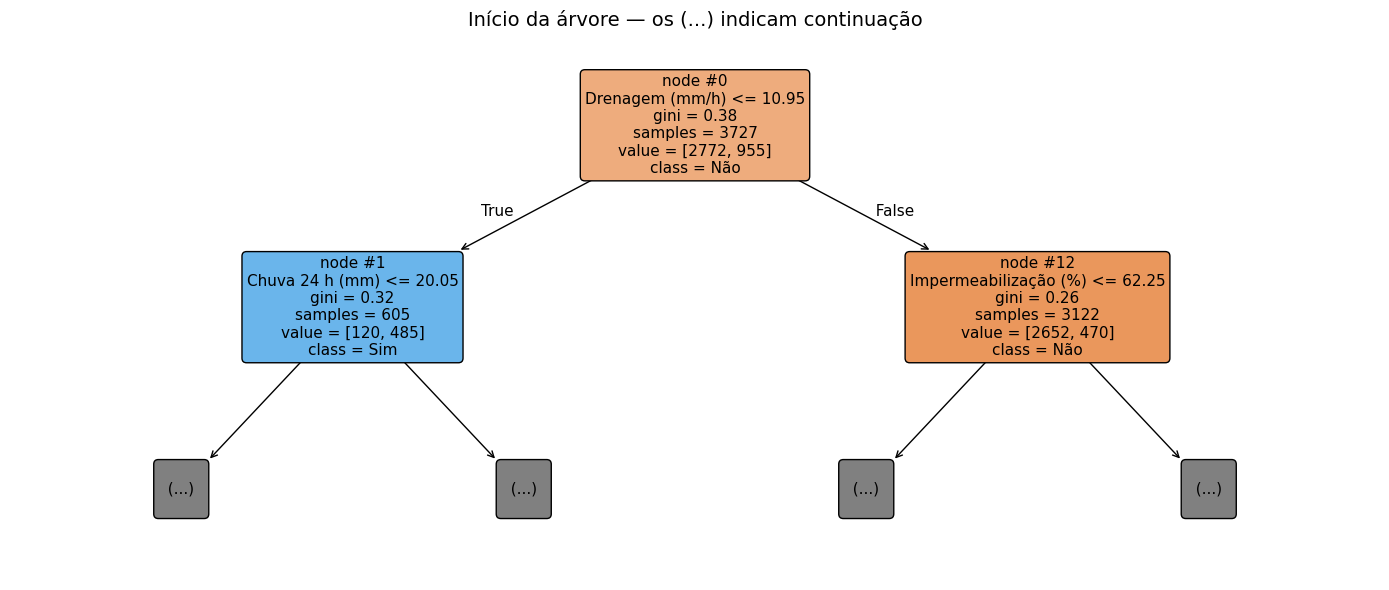

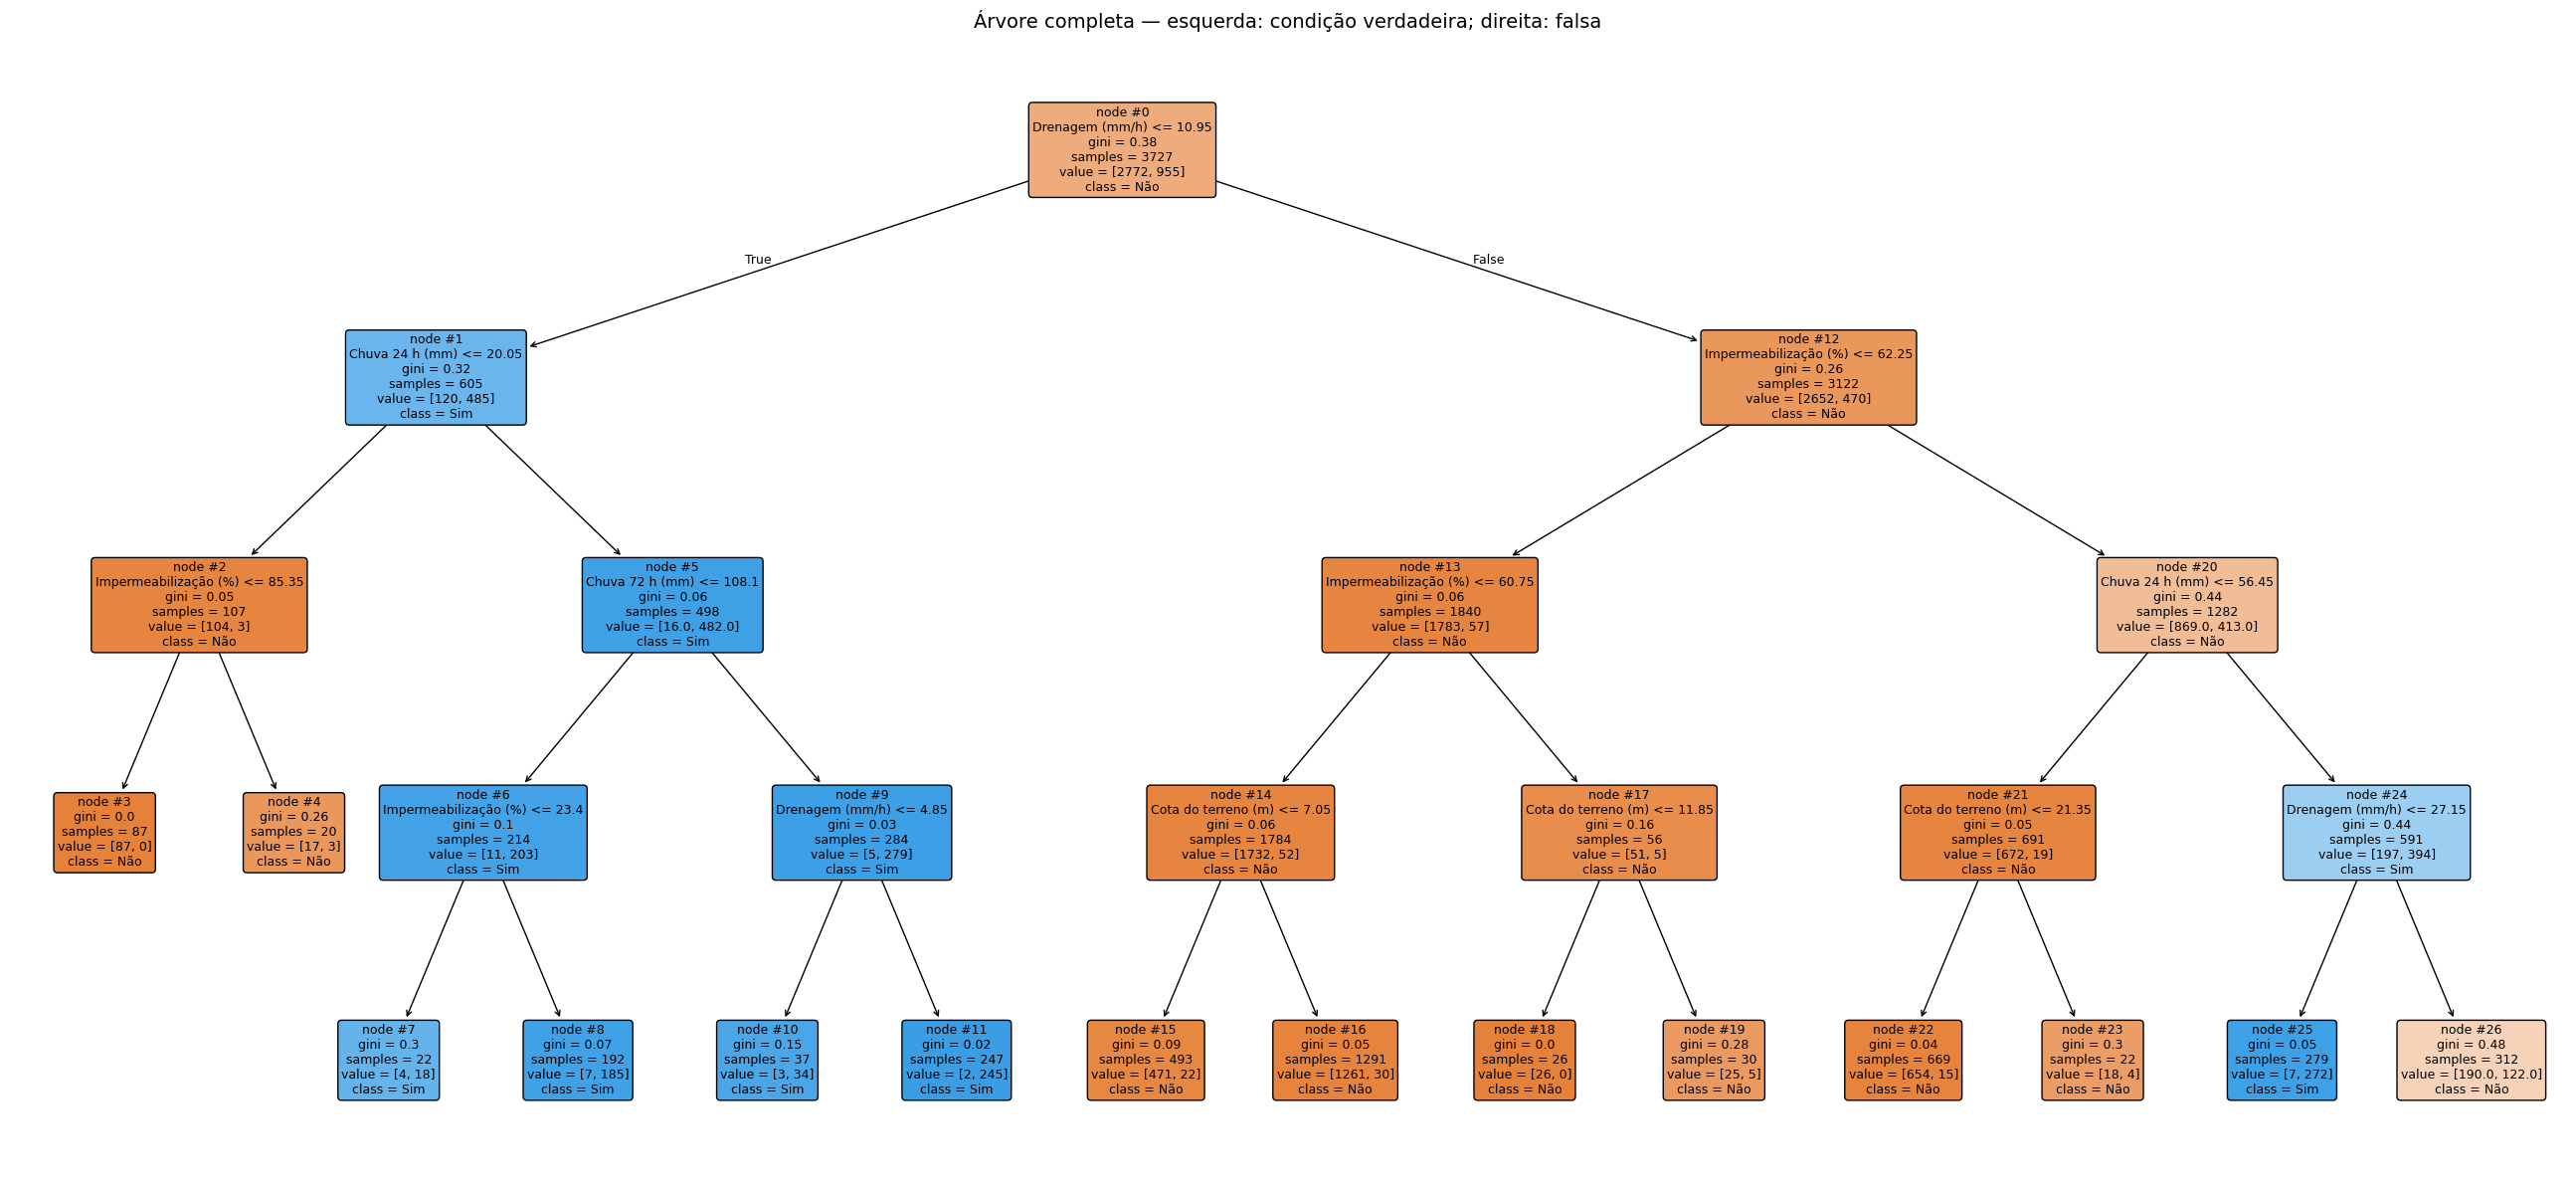

Profundidade: 4 | Folhas: 14


In [8]:
ROTULOS = {
    'chuva_24h_mm': 'Chuva 24 h (mm)', 'impermeabilizacao_pct': 'Impermeabilização (%)',
    'capacidade_drenagem_mm_h': 'Drenagem (mm/h)', 'chuva_72h_mm': 'Chuva 72 h (mm)',
    'cota_terreno_m': 'Cota do terreno (m)', 'execucao_fisica_pct': 'Execução física (%)',
    'dias_restantes': 'Dias restantes', 'pendencias_tecnicas': 'Pendências técnicas',
    'repasse_em_dia': 'Repasse em dia (0/1)', 'prazo_previsto_dias': 'Prazo previsto (dias)',
    'dias_chuva_30d': 'Dias de chuva', 'equipes_ativas': 'Equipes ativas',
    'valor_contrato_reais': 'Valor do contrato (R$)', 'vistorias_30d': 'Vistorias em 30 dias'
}

def desenhar_arvore(modelo, colunas, nome, classes=None):
    nomes = [ROTULOS.get(c, c.replace('_', ' ')) for c in colunas]
    pasta = PASTA / 'arvores'
    pasta.mkdir(exist_ok=True)
    for profundidade, tamanho, fonte in [(1, (14, 6), 11), (None, (26, 12), 9)]:
        fig, ax = plt.subplots(figsize=tamanho)
        plot_tree(modelo, feature_names=nomes, class_names=classes, filled=True,
                  rounded=True, node_ids=True, precision=2, fontsize=fonte,
                  max_depth=profundidade, ax=ax)
        ax.set_title('Início da árvore — os (...) indicam continuação' if profundidade == 1
                     else 'Árvore completa — esquerda: condição verdadeira; direita: falsa', fontsize=14)
        fig.tight_layout()
        if profundidade is None:
            fig.savefig(pasta / f'{nome}.svg', bbox_inches='tight')
        plt.show()
    print(f'Profundidade: {modelo.get_depth()} | Folhas: {modelo.get_n_leaves()}')

arvore_c = modelos_c['Árvore de classificação']
desenhar_arvore(arvore_c, X_c.columns, 'arvore_alagamento', ['Não', 'Sim'])

### 2.6 Caminho de um registro

Vamos acompanhar um único registro de teste. O quadro abaixo usa a árvore treinada e mostra o valor consultado, o corte e a direção tomada. Na folha, a previsão vem da distribuição dos casos de treino que chegaram até ela.

In [9]:
def mostrar_caminho(modelo, registro):
    estrutura = modelo.tree_
    no, passos = 0, []
    while estrutura.children_left[no] != estrutura.children_right[no]:
        coluna = registro.columns[estrutura.feature[no]]
        valor = float(registro.iloc[0][coluna])
        corte = estrutura.threshold[no]
        esquerda = valor <= corte
        proximo = estrutura.children_left[no] if esquerda else estrutura.children_right[no]
        passos.append({'Nó': no, 'Variável': coluna, 'Valor do caso': valor,
                       'Corte (≤)': corte, 'Resposta': 'Sim → esquerda' if esquerda else 'Não → direita',
                       'Próximo nó': int(proximo)})
        no = proximo
    display(pd.DataFrame(passos))
    print(f'Folha {no}: {estrutura.n_node_samples[no]} registros de treino.')
    print(f'Previsão: {modelo.predict(registro)[0]:.2f}')
    return no

caso_c = Xc_teste.iloc[[0]]
display(caso_c)
folha_c = mostrar_caminho(arvore_c, caso_c)
print('Resultado real:', yc_teste.iloc[0])
print('Probabilidade estimada de alagamento:', round(arvore_c.predict_proba(caso_c)[0, 1], 3))

,chuva_24h_mm,impermeabilizacao_pct,capacidade_drenagem_mm_h,chuva_72h_mm,cota_terreno_m,chuva_72h_mm_ausente,cota_terreno_m_ausente
1141,100.200,27.800,39.200,113.300,17.100,0,0


,Nó,Variável,Valor do caso,Corte (≤),Resposta,Próximo nó
0,0,capacidade_drenagem_mm_h,39.200,10.950,Não → direita,12
1,12,impermeabilizacao_pct,27.800,62.250,Sim → esquerda,13
2,13,impermeabilizacao_pct,27.800,60.750,Sim → esquerda,14
3,14,cota_terreno_m,17.100,7.050,Não → direita,16


Folha 16: 1291 registros de treino.
Previsão: 0.00
Resultado real: 0
Probabilidade estimada de alagamento: 0.023


## 3. Gestão de Contratos — regressão

Agora a pergunta é: **quantos dias de atraso a entrega terá?** Essa medida permite discutir a intensidade do atraso. Se o objetivo fosse apenas responder “sim/não”, estaríamos diante de outra classificação.

Cada linha corresponde a uma obra acompanhada antes do encerramento, em um contrato diferente. As entradas são as condições conhecidas naquele momento; `atraso_dias` é o resultado observado posteriormente. Zero indica entrega sem atraso. Não usaremos informações apuradas somente depois da entrega como entrada.

| Coluna | O que representa |
|---|---|
| contrato_id | Identificação do contrato; será retirada da modelagem |
| prazo_previsto_dias | Duração total prevista no contrato |
| execucao_fisica_pct | Percentual já executado no acompanhamento |
| dias_restantes | Dias que ainda faltavam até o prazo contratual |
| pendencias_tecnicas | Quantidade de pendências abertas |
| repasse_em_dia | Situação do repasse: Sim ou Não |
| dias_chuva_30d | Dias com chuva nos 30 dias anteriores |
| equipes_ativas | Quantidade de equipes em atividade |
| valor_contrato_reais | Valor contratado, em reais |
| vistorias_30d | Vistorias realizadas nos 30 dias anteriores |
| atraso_dias | Dias de atraso na entrega; será o alvo |

8,000 linhas e 11 colunas


,contrato_id,prazo_previsto_dias,execucao_fisica_pct,dias_restantes,pendencias_tecnicas,repasse_em_dia,dias_chuva_30d,equipes_ativas,valor_contrato_reais,vistorias_30d,atraso_dias
0,OBR00001,117,47.300,36,2,Sim,6.000,1.000,4288224.08,NaN,42.100
1,OBR00002,391,45.000,37,1,Sim,3.000,2.000,1121355.31,NaN,35.100
2,OBR00003,317,77.700,123,6,Sim,15.000,5.000,1118687.17,5.000,4.100
3,OBR00004,427,28.100,137,6,Não,5.000,4.000,1859141.57,1.000,110.100
4,OBR00005,313,16.300,86,2,Sim,20.000,8.000,1339676.87,1.000,16.800


,Ausentes,Percentual (%)
contrato_id,0,0.000
prazo_previsto_dias,0,0.000
execucao_fisica_pct,0,0.000
dias_restantes,0,0.000
pendencias_tecnicas,0,0.000
repasse_em_dia,0,0.000
dias_chuva_30d,640,8.000
equipes_ativas,400,5.000
valor_contrato_reais,800,10.000
vistorias_30d,2400,30.000


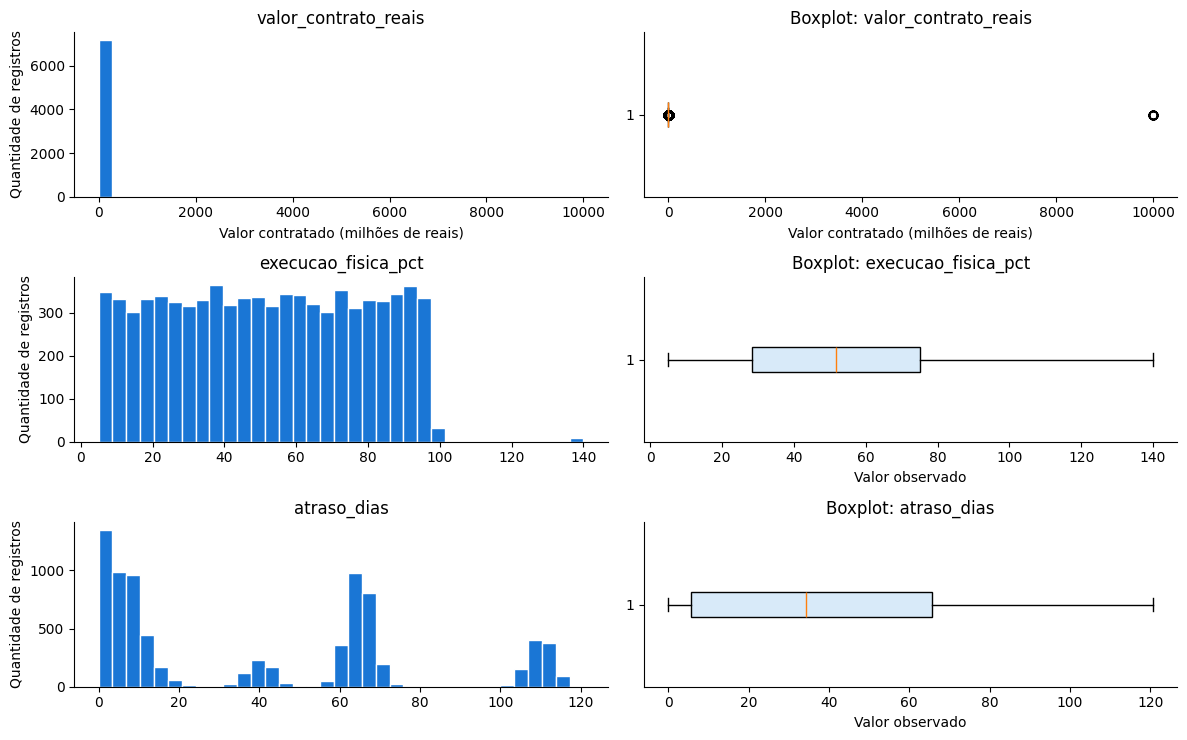

,Valor contratado
Mínimo,"23,034.490"
Mediana,"871,412.345"
Percentil 90,"3,011,355.688"
Percentil 95,"4,276,752.780"
Percentil 99,"9,351,048.082"
Máximo,"9,999,999,999.000"
Assimetria,14.903
Limite inferior do boxplot,"-1,385,845.764"
Limite superior do boxplot,"3,516,211.146"
Pontos fora desses limites,535.000


In [10]:
contratos_bruta = pd.read_csv(PASTA / 'Aula_14_contratos.csv', sep=';', encoding='utf-8-sig')
print(f'{contratos_bruta.shape[0]:,} linhas e {contratos_bruta.shape[1]} colunas')
display(contratos_bruta.head())
display(resumo_ausentes(contratos_bruta))

def formatar_contratos(dados):
    d = dados.copy()
    if d['repasse_em_dia'].dtype == 'object' or pd.api.types.is_string_dtype(d['repasse_em_dia']):
        d['repasse_em_dia'] = d['repasse_em_dia'].astype('string').str.strip().str.lower().map(
            {'sim': 1, 'não': 0, 'nao': 0, '1': 1, '0': 0})
    for coluna in d.columns.difference(['contrato_id']):
        d[coluna] = converter_numeros(d[coluna])
    return d

contratos_formatada = formatar_contratos(contratos_bruta)
distribuicoes(contratos_formatada, ['valor_contrato_reais', 'execucao_fisica_pct', 'atraso_dias'])
display(analisar_cauda(contratos_formatada['valor_contrato_reais']).to_frame('Valor contratado'))

### 3.1 Limpeza e dados ausentes

O cadastro deste exercício reúne obras de até **R$ 20 milhões**. O valor próximo de R$ 10 bilhões é um erro de preenchimento inserido na base. Vamos convertê-lo em ausente e depois preenchê-lo. Contratos de valor alto, mas dentro do escopo, serão preservados. Também retiraremos linhas com execução acima de 100% ou dias restantes negativos, incompatíveis com este recorte de acompanhamento anterior ao prazo.

As referências fixas para os ausentes serão: **R$ 1 milhão**, **4 equipes**, **10 dias de chuva** e **3 vistorias**. São valores didáticos previamente definidos, não estimativas obtidas do teste. Os indicadores de preenchimento serão mantidos. O alvo não será preenchido nem aparado para melhorar as métricas.

Removidas: 16 | Mantidas: 7984


,Ausentes,Percentual (%)
prazo_previsto_dias,0,0.000
execucao_fisica_pct,0,0.000
dias_restantes,0,0.000
pendencias_tecnicas,0,0.000
repasse_em_dia,0,0.000
dias_chuva_30d,0,0.000
equipes_ativas,0,0.000
valor_contrato_reais,0,0.000
vistorias_30d,0,0.000
atraso_dias,0,0.000


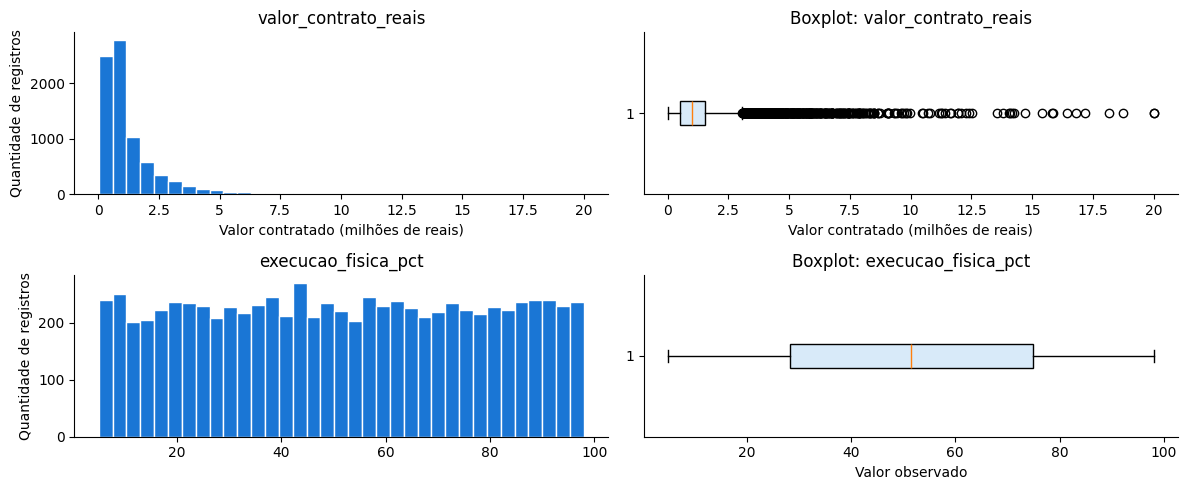

,Após a limpeza
Mínimo,"23,034.490"
Mediana,"998,692.970"
Percentil 90,"2,771,586.490"
Percentil 95,"3,893,744.860"
Percentil 99,"7,456,515.393"
Máximo,"20,000,000.000"
Assimetria,4.222
Limite inferior do boxplot,"-1,054,127.311"
Limite superior do boxplot,"3,076,030.839"
Pontos fora desses limites,663.000


In [11]:
REFERENCIAS_CONTRATOS = {'valor_contrato_reais': 1_000_000., 'equipes_ativas': 4.,
                          'dias_chuva_30d': 10., 'vistorias_30d': 3.}

def limpar_contratos(dados):
    d = formatar_contratos(dados).drop_duplicates().copy()
    valido = (d['execucao_fisica_pct'].between(0, 100) &
              d['dias_restantes'].between(0, 600) &
              d['prazo_previsto_dias'].between(1, 1000) &
              (d['dias_restantes'] <= d['prazo_previsto_dias']) &
              d['pendencias_tecnicas'].between(0, 30) & d['repasse_em_dia'].isin([0, 1]))
    if 'atraso_dias' in d:
        valido &= d['atraso_dias'].notna() & (d['atraso_dias'] >= 0)
    d = d.loc[valido].drop(columns=['contrato_id'], errors='ignore').copy()
    limites = {'valor_contrato_reais': (1, 20_000_000), 'equipes_ativas': (1, 30),
               'dias_chuva_30d': (0, 30), 'vistorias_30d': (0, 100)}
    for coluna, (minimo, maximo) in limites.items():
        d.loc[~d[coluna].between(minimo, maximo), coluna] = np.nan
        d[coluna + '_ausente'] = d[coluna].isna().astype(int)
        d[coluna] = d[coluna].fillna(REFERENCIAS_CONTRATOS[coluna])
    return d

contratos = limpar_contratos(contratos_bruta)
print(f'Removidas: {len(contratos_bruta) - len(contratos)} | Mantidas: {len(contratos)}')
display(resumo_ausentes(contratos))
distribuicoes(contratos, ['valor_contrato_reais', 'execucao_fisica_pct'])
display(analisar_cauda(contratos['valor_contrato_reais']).to_frame('Após a limpeza'))

### 3.2 Cauda longa e relação com o atraso

Há muitos contratos de valor menor e poucos de valor elevado. A escala logarítmica comprime as diferenças e ajuda a visualizar essa cauda longa. O gráfico com `log1p` é apenas uma ferramenta de análise; os modelos receberão os valores originais tratados.

O boxplot por faixa de execução mostra como o atraso se distribui em grupos diferentes. A linha dentro da caixa é a mediana; a caixa contém a metade central dos valores. Pontos externos aos bigodes merecem análise, mas podem ser atrasos reais e relevantes.

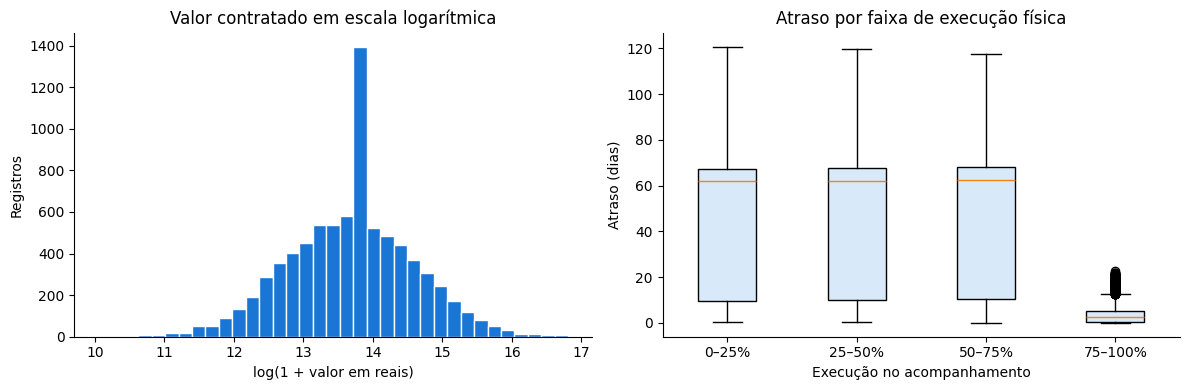

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log1p(contratos['valor_contrato_reais']), bins=35, color=AZUL, edgecolor='white')
ax[0].set(title='Valor contratado em escala logarítmica', xlabel='log(1 + valor em reais)', ylabel='Registros')
faixas = pd.cut(contratos['execucao_fisica_pct'], [0, 25, 50, 75, 100], include_lowest=True)
grupos = [contratos.loc[faixas == faixa, 'atraso_dias'] for faixa in faixas.cat.categories]
ax[1].boxplot(grupos, patch_artist=True, boxprops={'facecolor': '#D8EAF9'})
ax[1].set(xticks=[1, 2, 3, 4], xticklabels=['0–25%', '25–50%', '50–75%', '75–100%'],
          title='Atraso por faixa de execução física', xlabel='Execução no acompanhamento', ylabel='Atraso (dias)')
plt.tight_layout(); plt.show()

### 3.3 Comparação dos modelos

Vamos comparar **regressão linear**, **regressão linear Ridge**, **regressão linear Lasso**, **regressão linear Elastic Net** e **árvore de regressão**. Os quatro primeiros combinam as entradas de forma linear. Ridge, Lasso e Elastic Net controlam os coeficientes, mas essa regularização, sozinha, não cria as mudanças de regra entre faixas.

Usaremos os mesmos registros para todos os modelos. A validação cruzada escolherá as configurações pelo menor RMSE. O teste permanecerá reservado para a tabela final. A busca da árvore ficará limitada a quatro níveis, para que possamos ler sua estrutura completa em aula.

In [13]:
X_r = contratos.drop(columns='atraso_dias')
y_r = contratos['atraso_dias']
Xr_treino, Xr_teste, yr_treino, yr_teste = train_test_split(
    X_r, y_r, test_size=.25, random_state=SEMENTE)
cv_r = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
buscas_r = {
    'Regressão linear': GridSearchCV(make_pipeline(StandardScaler(), LinearRegression()),
        {}, scoring='neg_root_mean_squared_error', cv=cv_r),
    'Regressão linear Ridge': GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
        {'ridge__alpha': [.01, .1, 1, 10, 100]}, scoring='neg_root_mean_squared_error', cv=cv_r),
    'Regressão linear Lasso': GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
        {'lasso__alpha': [.001, .01, .1, 1]}, scoring='neg_root_mean_squared_error', cv=cv_r),
    'Regressão linear Elastic Net': GridSearchCV(
        make_pipeline(StandardScaler(), ElasticNet(max_iter=10000)),
        {'elasticnet__alpha': [.001, .01, .1, 1], 'elasticnet__l1_ratio': [.2, .5, .8]},
        scoring='neg_root_mean_squared_error', cv=cv_r),
    'Árvore de regressão': GridSearchCV(DecisionTreeRegressor(random_state=SEMENTE),
        {'max_depth': [2, 3, 4], 'min_samples_leaf': [30, 75, 150]},
        scoring='neg_root_mean_squared_error', cv=cv_r)
}
for busca in buscas_r.values():
    busca.fit(Xr_treino, yr_treino)
display(pd.DataFrame([{'Modelo': nome, 'RMSE na validação (dias)': -busca.best_score_,
                       'Configuração': busca.best_params_} for nome, busca in buscas_r.items()]))

,Modelo,RMSE na validação (dias),Configuração
0,Regressão linear,26.060,{}
1,Regressão linear Ridge,26.060,{'ridge__alpha': 10}
2,Regressão linear Lasso,26.052,{'lasso__alpha': 0.1}
3,Regressão linear Elastic Net,26.059,"{'elasticnet__alpha': 0.01, 'elasticnet__l1_ra..."
4,Árvore de regressão,2.889,"{'max_depth': 4, 'min_samples_leaf': 30}"


### 3.4 Avaliação da regressão

**R²** compara os erros do modelo com uma referência baseada na média do resultado real do conjunto avaliado. Seu melhor valor é 1; zero indica o mesmo erro quadrático dessa referência; valores negativos são possíveis. Não é porcentagem de previsões corretas.

**MSE** é a média dos erros ao quadrado, em **dias²**. **RMSE** é a raiz do MSE e volta à unidade original, **dias**. Valores menores indicam menos erro. Como RMSE é a raiz do MSE, as duas métricas produzem a mesma ordenação nesta comparação.

Também mostraremos uma previsão constante baseada na média do treino. Não vamos cortar previsões negativas dos modelos lineares: a tabela deve mostrar o comportamento aprendido por cada modelo.

,R²,MSE (dias²),RMSE (dias)
Modelo,,,
Árvore de regressão,0.994,8.353,2.890
Regressão linear,0.521,685.371,26.180
Regressão linear Ridge,0.521,685.391,26.180
Regressão linear Elastic Net,0.521,685.402,26.180
Regressão linear Lasso,0.521,685.600,26.184
Sempre a média do treino,-0.000,"1,432.060",37.843


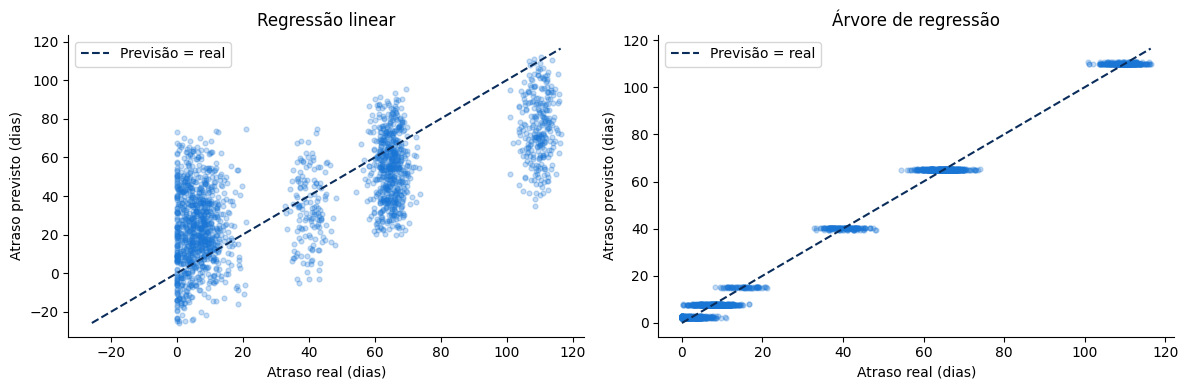

In [14]:
modelos_r = {nome: busca.best_estimator_ for nome, busca in buscas_r.items()}
previsoes_r = {nome: modelo.predict(Xr_teste) for nome, modelo in modelos_r.items()}
avaliacoes_r = {'Sempre a média do treino': np.full(len(yr_teste), yr_treino.mean()), **previsoes_r}
resultados_r = pd.DataFrame([
    {'Modelo': nome, 'R²': r2_score(yr_teste, pred),
     'MSE (dias²)': mean_squared_error(yr_teste, pred),
     'RMSE (dias)': root_mean_squared_error(yr_teste, pred)}
    for nome, pred in avaliacoes_r.items()]).set_index('Modelo')
display(resultados_r.sort_values('RMSE (dias)'))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for ax, nome in zip(eixos, ['Regressão linear', 'Árvore de regressão']):
    pred = previsoes_r[nome]
    ax.scatter(yr_teste, pred, s=12, alpha=.25, color=AZUL)
    extremos = [min(yr_teste.min(), pred.min()), max(yr_teste.max(), pred.max())]
    ax.plot(extremos, extremos, '--', color=AZUL_ESCURO, label='Previsão = real')
    ax.set(title=nome, xlabel='Atraso real (dias)', ylabel='Atraso previsto (dias)')
    ax.legend()
plt.tight_layout(); plt.show()

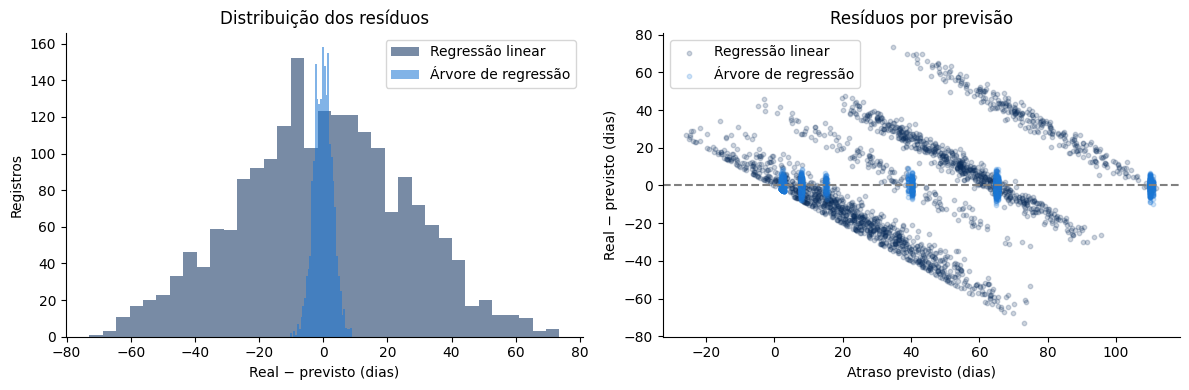

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for nome, cor in [('Regressão linear', AZUL_ESCURO), ('Árvore de regressão', AZUL)]:
    residuos = yr_teste.to_numpy() - previsoes_r[nome]
    eixos[0].hist(residuos, bins=35, alpha=.55, label=nome, color=cor)
    eixos[1].scatter(previsoes_r[nome], residuos, s=10, alpha=.2, label=nome, color=cor)
eixos[0].set(title='Distribuição dos resíduos', xlabel='Real − previsto (dias)', ylabel='Registros')
eixos[1].axhline(0, color='gray', linestyle='--')
eixos[1].set(title='Resíduos por previsão', xlabel='Atraso previsto (dias)', ylabel='Real − previsto (dias)')
for ax in eixos: ax.legend()
plt.tight_layout(); plt.show()

Um resíduo positivo indica que o atraso real foi maior que o previsto: o modelo subestimou o atraso. Um resíduo negativo indica superestimação. A concentração perto de zero é desejável, mas também precisamos observar se os erros crescem em certas faixas.

Os modelos lineares podem ficar próximos entre si. Isso é coerente: a regularização muda o tamanho dos coeficientes, mas todos mantêm a mesma forma de relação. A árvore consegue separar regimes diferentes de atraso. Esta vantagem foi planejada na simulação; em uma aplicação real, será preciso verificá-la em dados novos.

### 3.5 Árvore de regressão e caminho da previsão

O percurso é o mesmo da classificação: começamos na raiz, respondemos à condição de cada caixa e seguimos à esquerda quando ela é verdadeira ou à direita quando é falsa. A diferença está na resposta: **a folha prevê uma quantidade de dias, e não uma classe “sim” ou “não”.**

Na árvore desta aula, a primeira pergunta é `Pendências técnicas <= 2.5`. Como contamos pendências em números inteiros, contratos com **0, 1 ou 2 pendências seguem à esquerda**; contratos com **3 ou mais seguem à direita**. O corte 2,5 apenas separa esses dois grupos: não significa que exista meia pendência. Depois, seguimos a próxima pergunta daquele ramo.

| Informação na caixa | Como interpretar |
|---|---|
| `node #...` | Número que identifica o nó no desenho e no quadro do caminho. |
| Condição `variável <= corte` | Pergunta que determina o próximo ramo. Uma folha não tem essa pergunta. |
| `samples` | Quantidade de contratos de treino que chegaram ao nó. |
| `value` | Média dos atrasos dos contratos de treino naquele nó, em dias. **Na folha, esse é o valor previsto para o novo contrato.** |
| `squared_error` | Média dos desvios ao quadrado em relação à média do próprio nó. Mede quanto os atrasos daquele grupo se espalham, em dias². Não é o MSE calculado no teste. |

**Exemplo de leitura de uma folha.** Imagine uma folha com três contratos cujos atrasos foram 4, 6 e 8 dias. Ela teria `samples = 3` e `value = 6`, pois (4 + 6 + 8) ÷ 3 = 6. Um novo contrato que percorresse esse mesmo caminho receberia a previsão de **6 dias de atraso**. Isso não significa que os três contratos atrasaram exatamente 6 dias: essa é a média usada para representar o grupo.

Nesse exemplo, `squared_error` seria aproximadamente **2,67 dias²**: calculamos os desvios em relação a 6, elevamos ao quadrado e tiramos a média. Grupos com atrasos mais próximos tendem a ter esse valor menor. A árvore procura divisões que reduzam essa dispersão no treino; o desempenho em novos contratos é avaliado separadamente no teste.

Aqui, a cor não representa “Sim” e “Não”. **O laranja mais intenso indica maior atraso médio previsto**, e as caixas mais claras indicam menor atraso médio. A intensidade da cor não mede a confiança nem a precisão da previsão.

Para ler um caso completo, siga as condições até uma folha e consulte seu `value`. O quadro abaixo do gráfico repete esse percurso usando os valores de um contrato de teste. A última conta confirma que a previsão é igual à média dos atrasos dos registros de treino da folha alcançada. A árvore não prolonga uma tendência: casos novos são encaminhados às folhas que ela já aprendeu.

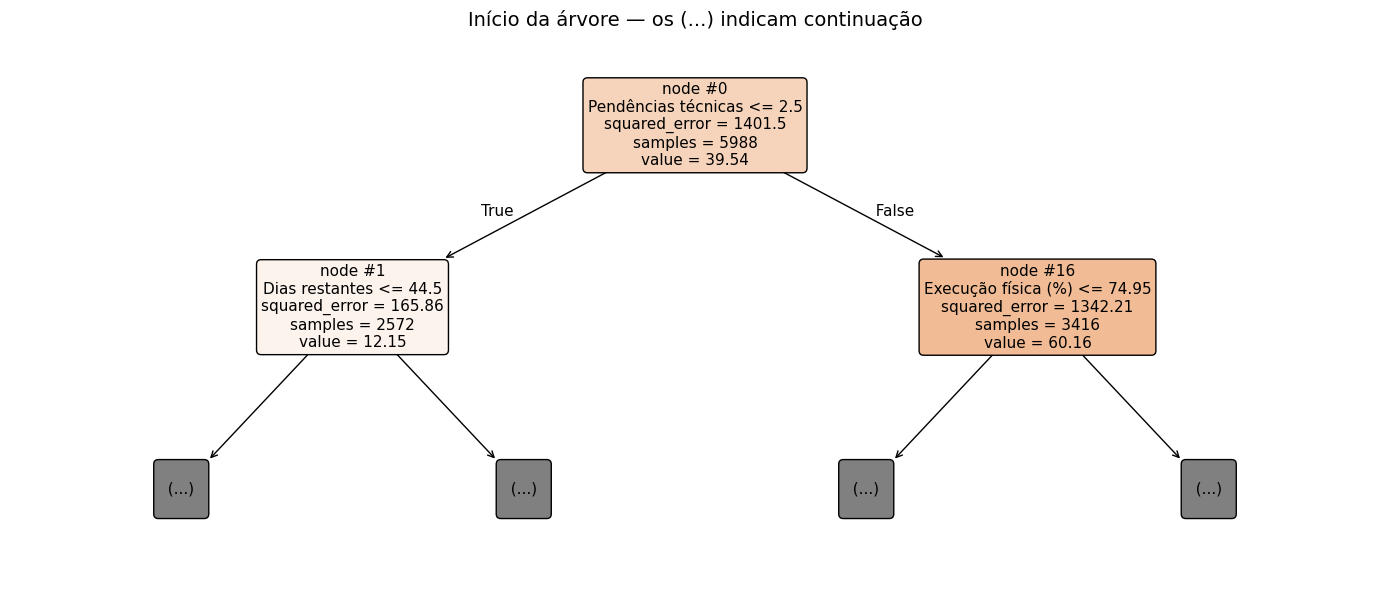

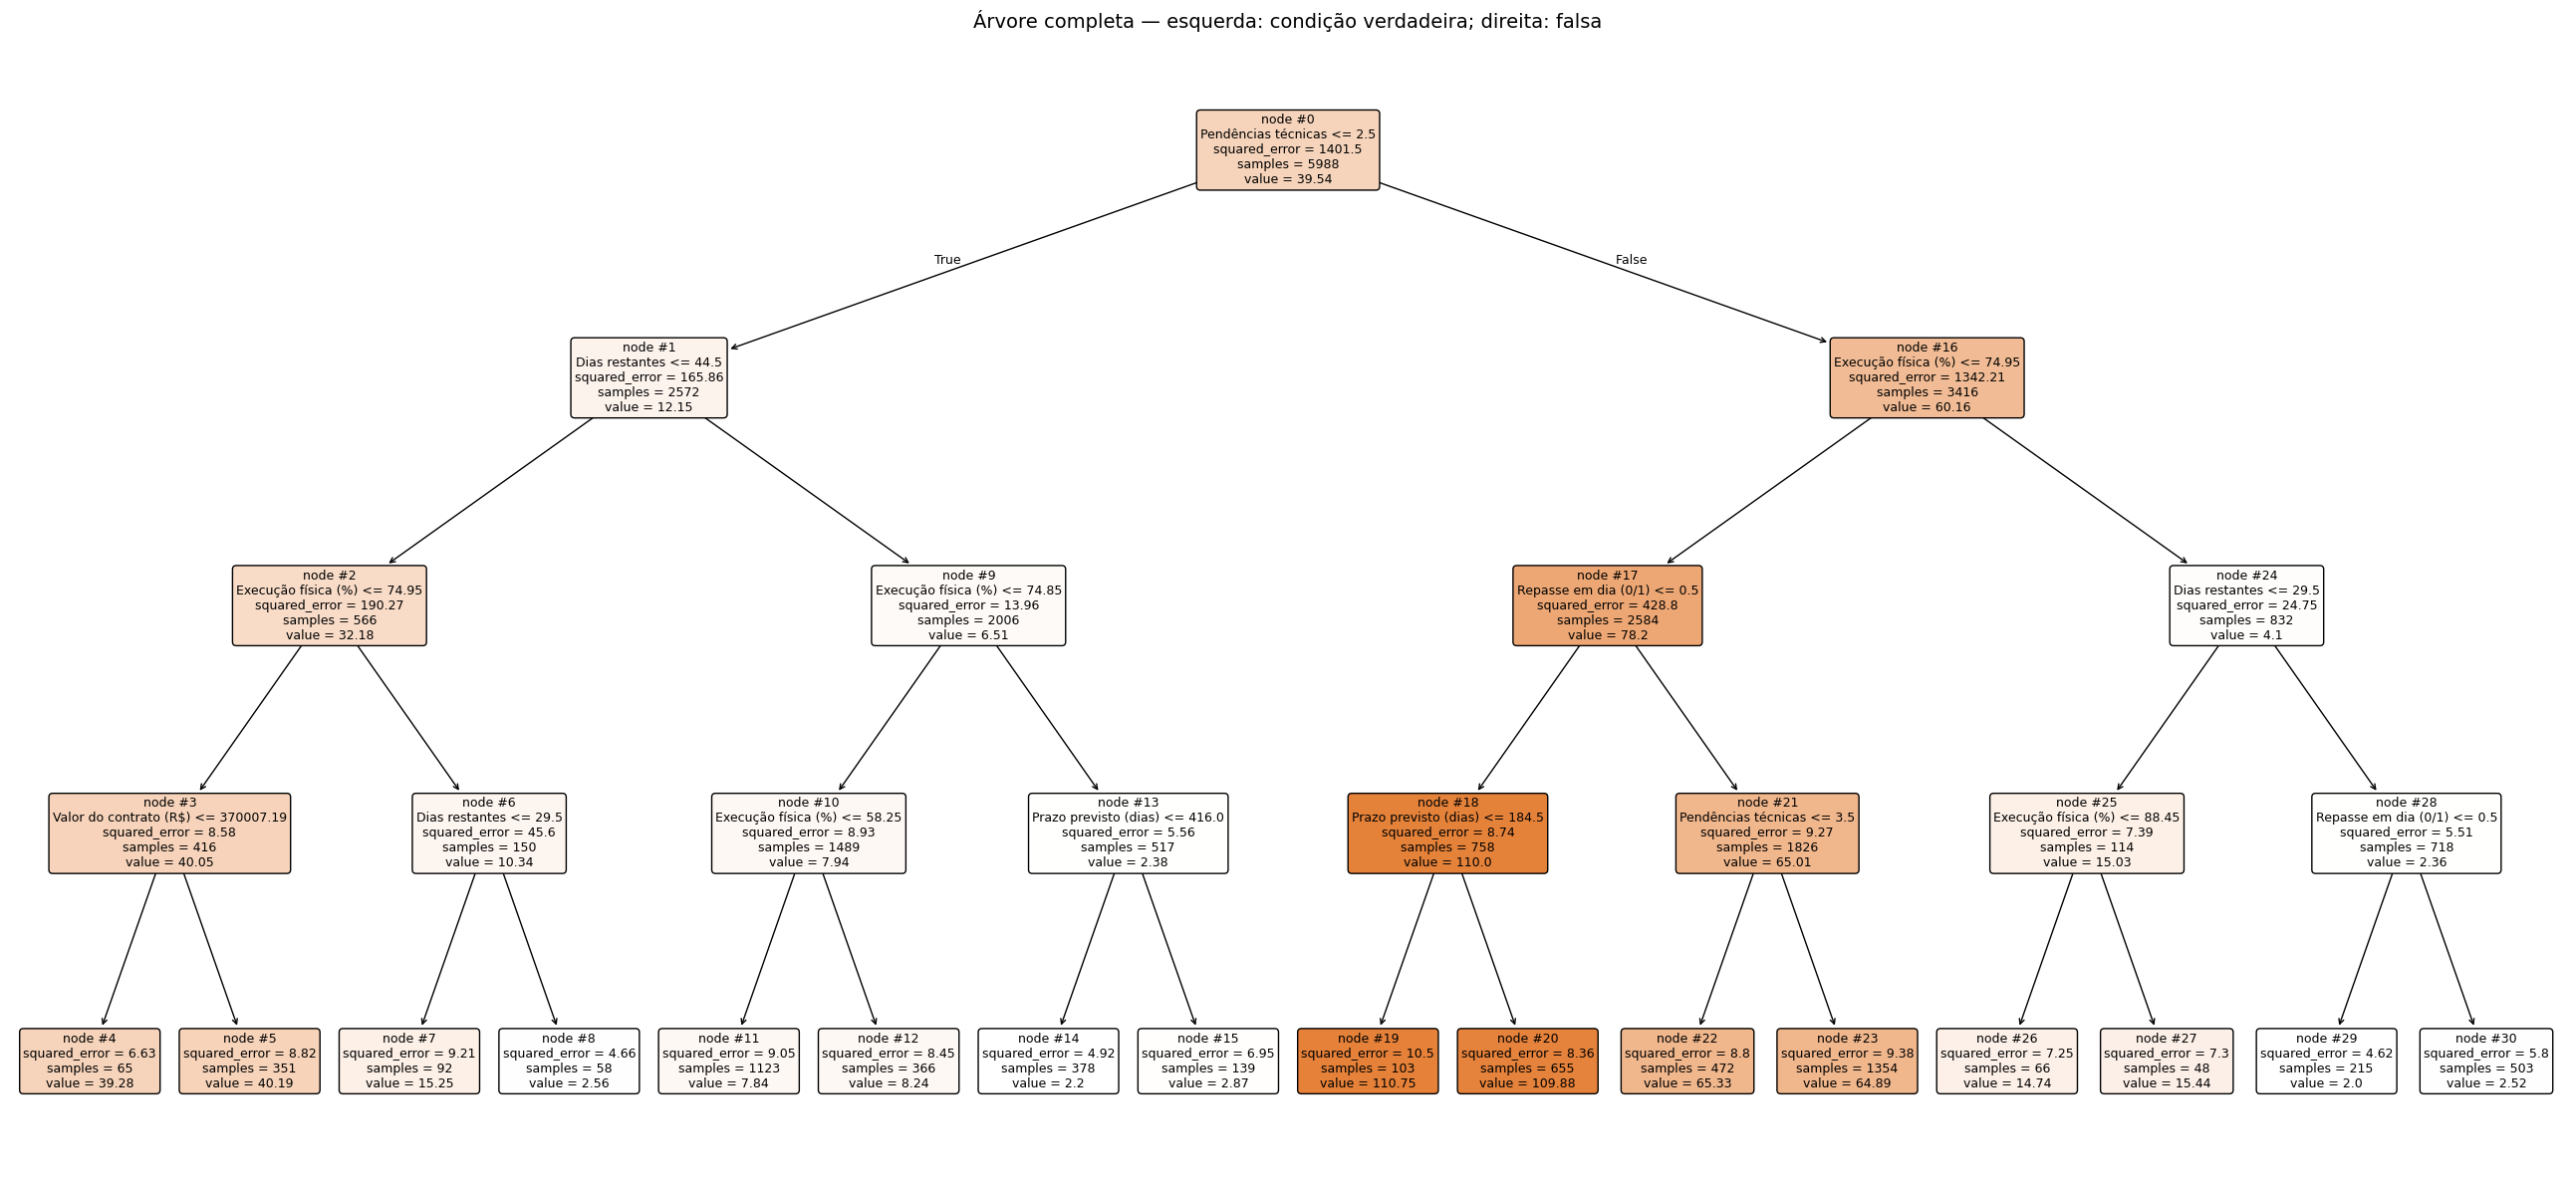

Profundidade: 4 | Folhas: 16


,prazo_previsto_dias,execucao_fisica_pct,dias_restantes,pendencias_tecnicas,repasse_em_dia,dias_chuva_30d,equipes_ativas,valor_contrato_reais,vistorias_30d,valor_contrato_reais_ausente,equipes_ativas_ausente,dias_chuva_30d_ausente,vistorias_30d_ausente
5022,349,81.100,172,1,1,4.000,4.000,"615,198.680",7.000,0,0,0,0


,Nó,Variável,Valor do caso,Corte (≤),Resposta,Próximo nó
0,0,pendencias_tecnicas,1.000,2.500,Sim → esquerda,1
1,1,dias_restantes,172.000,44.500,Não → direita,9
2,9,execucao_fisica_pct,81.100,74.850,Não → direita,13
3,13,prazo_previsto_dias,349.000,416.000,Sim → esquerda,14


Folha 14: 378 registros de treino.
Previsão: 2.20
Média dos atrasos no treino desta folha: 2.20 dias
Atraso real do caso de teste: 1.5 dias


In [16]:
arvore_r = modelos_r['Árvore de regressão']
desenhar_arvore(arvore_r, X_r.columns, 'arvore_atraso')

caso_r = Xr_teste.iloc[[0]]
display(caso_r)
folha_r = mostrar_caminho(arvore_r, caso_r)
folhas_treino = arvore_r.apply(Xr_treino)
media_folha = yr_treino.loc[folhas_treino == folha_r].mean()
print(f'Média dos atrasos no treino desta folha: {media_folha:.2f} dias')
print(f'Atraso real do caso de teste: {yr_teste.iloc[0]:.1f} dias')

## 4. Previsão com informações digitadas

Agora vamos informar **um caso novo**, sem fornecer sua resposta. Usaremos as árvores já treinadas: `arvore_c` para prever alagamento e `arvore_r` para prever dias de atraso. Elas obtiveram o melhor desempenho nas comparações desta aula. Não vamos treinar novamente ao digitar um caso.

Primeiro, execute as células anteriores para preparar os dados, treinar os modelos e definir as funções. Depois, execute a célula do exemplo desejado em **4.1** ou **4.2**. Os campos aparecerão um de cada vez: digite o valor e pressione Enter. Aceitamos ponto ou vírgula decimal, sem separador de milhar; nos campos opcionais, Enter sozinho registra ausência.

As funções aplicam o mesmo tratamento e a mesma ordem de colunas utilizados no treino. A saída mostra a previsão e o caminho percorrido na árvore. Para testar outro caso, basta executar novamente a mesma célula. Se usar “Executar tudo”, o notebook também fará essas perguntas e aguardará suas respostas.

In [17]:
def ler_numero(pergunta, minimo, maximo, opcional=False, inteiro=False):
    while True:
        resposta = input(pergunta + (' [Enter = ausente]' if opcional else '') + ': ').strip()
        if opcional and resposta == '':
            return np.nan
        try:
            valor = float(resposta.replace(',', '.'))
            if np.isfinite(valor) and minimo <= valor <= maximo and (not inteiro or valor.is_integer()):
                return valor
        except ValueError:
            pass
        print(f'Informe um número {"inteiro " if inteiro else ""}entre {minimo} e {maximo}.')

def prever_alagamento():
    chuva = ler_numero('Chuva em 24 h (mm)', 0, 300)
    entrada = {'chuva_24h_mm': chuva,
        'impermeabilizacao_pct': ler_numero('Área impermeável (%)', 0, 100),
        'capacidade_drenagem_mm_h': ler_numero('Capacidade de drenagem (mm/h)', 0, 60),
        'chuva_72h_mm': ler_numero('Chuva em 72 h (mm)', chuva, 900, opcional=True),
        'cota_terreno_m': ler_numero('Cota do terreno (m)', 0, 100, opcional=True)}
    registro = limpar_civil(pd.DataFrame([entrada])).reindex(columns=X_c.columns)
    classe = int(arvore_c.predict(registro)[0])
    probabilidade = arvore_c.predict_proba(registro)[0, 1]
    print(f'Previsão de alagamento: {"SIM" if classe else "NÃO"} | Probabilidade estimada: {probabilidade:.1%}')
    mostrar_caminho(arvore_c, registro)
    return registro

def prever_atraso():
    prazo = ler_numero('Prazo total previsto (dias)', 1, 1000, inteiro=True)
    entrada = {'prazo_previsto_dias': prazo,
        'execucao_fisica_pct': ler_numero('Execução física (%)', 0, 100),
        'dias_restantes': ler_numero('Dias restantes até o prazo', 0, min(prazo, 600), inteiro=True),
        'pendencias_tecnicas': ler_numero('Pendências técnicas abertas', 0, 30, inteiro=True),
        'repasse_em_dia': ler_numero('Repasse em dia? 1 = sim; 0 = não', 0, 1, inteiro=True),
        'dias_chuva_30d': ler_numero('Dias de chuva nos últimos 30 dias', 0, 30, opcional=True, inteiro=True),
        'equipes_ativas': ler_numero('Equipes ativas', 1, 30, opcional=True, inteiro=True),
        'valor_contrato_reais': ler_numero('Valor do contrato (R$, sem separador de milhar)', 1, 20_000_000, opcional=True),
        'vistorias_30d': ler_numero('Vistorias nos últimos 30 dias', 0, 100, opcional=True, inteiro=True)}
    registro = limpar_contratos(pd.DataFrame([entrada])).reindex(columns=X_r.columns)
    print(f'Atraso estimado: {arvore_r.predict(registro)[0]:.1f} dias')
    mostrar_caminho(arvore_r, registro)
    return registro

### 4.1 Novo caso — alagamento

Informe as condições da região no episódio de chuva. A árvore responderá **Sim** ou **Não** e mostrará a probabilidade estimada de alagamento. Não informe `houve_alagamento`: esse é justamente o resultado que queremos prever.

Execute a célula abaixo para começar.

In [18]:
novo_caso_alagamento = prever_alagamento()

Chuva em 24 h (mm): 80
Área impermeável (%): 40
Capacidade de drenagem (mm/h): 22
Chuva em 72 h (mm) [Enter = ausente]: 120
Cota do terreno (m) [Enter = ausente]: 10
Previsão de alagamento: NÃO | Probabilidade estimada: 2.3%


,Nó,Variável,Valor do caso,Corte (≤),Resposta,Próximo nó
0,0,capacidade_drenagem_mm_h,22.000,10.950,Não → direita,12
1,12,impermeabilizacao_pct,40.000,62.250,Sim → esquerda,13
2,13,impermeabilizacao_pct,40.000,60.750,Sim → esquerda,14
3,14,cota_terreno_m,10.000,7.050,Não → direita,16


Folha 16: 1291 registros de treino.
Previsão: 0.00


### 4.2 Novo caso — atraso de contrato

Informe a situação do contrato no momento do acompanhamento. Para o repasse, digite **1 = em dia** ou **0 = não está em dia**. A árvore retornará o **atraso estimado em dias**. Não informe `atraso_dias`, pois ele é a resposta a prever.

Execute a célula abaixo para começar.

In [19]:
novo_caso_contrato = prever_atraso()

Prazo total previsto (dias): 365
Execução física (%): 55
Dias restantes até o prazo: 310
Pendências técnicas abertas: 15
Repasse em dia? 1 = sim; 0 = não: 0
Dias de chuva nos últimos 30 dias [Enter = ausente]: 13
Equipes ativas [Enter = ausente]: 3
Valor do contrato (R$, sem separador de milhar) [Enter = ausente]: 2000000
Vistorias nos últimos 30 dias [Enter = ausente]: 1
Atraso estimado: 109.9 dias


,Nó,Variável,Valor do caso,Corte (≤),Resposta,Próximo nó
0,0,pendencias_tecnicas,15.000,2.500,Não → direita,16
1,16,execucao_fisica_pct,55.000,74.950,Sim → esquerda,17
2,17,repasse_em_dia,0.000,0.500,Sim → esquerda,18
3,18,prazo_previsto_dias,365.000,184.500,Não → direita,20


Folha 20: 655 registros de treino.
Previsão: 109.88


## 5. Discussão dos resultados

1. Na Defesa Civil, qual erro merece mais atenção: emitir um alerta indevido ou deixar de identificar um alagamento? Localize os dois na matriz de confusão.
2. Nos contratos, quanto o RMSE diminuiu ao passar da regressão linear para a árvore? Relacione essa diferença com os caminhos da árvore.
3. Por que eliminar todos os pontos externos ao boxplot poderia prejudicar os dois estudos?
4. Se aumentássemos muito a profundidade, uma melhora no treino seria suficiente para escolher a árvore maior?

Os testes usam divisões aleatórias porque os registros desta simulação são independentes. Em um projeto real, obras repetidas ou regiões observadas ao longo do tempo exigiriam uma divisão por contrato, região ou período, conforme o uso pretendido. O desempenho desta aula não deve ser apresentado como desempenho de um sistema municipal real.

Referências para consulta: [árvores de decisão](https://scikit-learn.org/stable/modules/tree.html), [validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html), [vazamento de informação](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) e [métricas de avaliação](https://scikit-learn.org/stable/modules/model_evaluation.html).